# ChainGuard · M4 — Graphe (GCN, GraphSAGE, hybride) et dérive temporelle

**Membre 4 (Laila)** · semaine 2 · prérequis : avoir exécuté `m4_baselines.ipynb` (il produit `data/processed/m4_test_preds.csv`).

Questions traitées :
1. **Le graphe apporte-t-il quelque chose ?** GCN et GraphSAGE contre les baselines tabulaires, sur le même split temporel.
2. **Peut-on combiner les deux ?** Random Forest sur features + embeddings GraphSAGE.
3. **Le modèle tient-il dans le temps ?** F1 par période de test, modèle figé contre réentraînement périodique.

**Cadre transductif** (standard sur Elliptic, à préciser dans le rapport) : le réseau voit tout le graphe, y compris les features des nœuds de test, mais jamais leurs labels.

In [1]:
import sys; sys.path.append('..')

import json, pathlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, SAGEConv
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

from src.common.metrics import evaluate
from src.m4.elliptic import load_elliptic

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
RESULTS = pathlib.Path("../results"); RESULTS.mkdir(exist_ok=True)
PROCESSED = pathlib.Path("../data/processed"); PROCESSED.mkdir(parents=True, exist_ok=True)

E = load_elliptic()
df, edges, feat_cols, lab, train, test = E.df, E.edges, E.feat_cols, E.lab, E.train, E.test
print(f"{len(df):,} nœuds, {len(edges):,} arêtes, {len(lab):,} étiquetés")

C:\s1\ai and blockchain\project\ChainGuard_M4_Laila\chainguard\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\s1\ai and blockchain\project\ChainGuard_M4_Laila\chainguard\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


203,769 nœuds, 234,355 arêtes, 46,564 étiquetés


## 1. Construire le graphe PyTorch Geometric

Les arêtes d'Elliptic sont orientées (flux de bitcoins). On les rend non orientées : une transaction illicite « contamine » aussi bien ses parents que ses enfants.

In [2]:
idx = pd.Series(np.arange(len(df)), index=df.txId.values)
src_i = edges.txId1.map(idx); dst_i = edges.txId2.map(idx)
ok = src_i.notna() & dst_i.notna()
if (~ok).any():
    print(f"{(~ok).sum()} arêtes ignorées (txId absent des features)")
src = torch.tensor(src_i[ok].astype(int).values, dtype=torch.long)
dst = torch.tensor(dst_i[ok].astype(int).values, dtype=torch.long)
edge_index = torch.cat([torch.stack([src, dst]), torch.stack([dst, src])], dim=1)

data = Data(x=torch.tensor(df[feat_cols].values, dtype=torch.float),
            edge_index=edge_index, y=torch.tensor(df.y.values, dtype=torch.long))
ts = torch.tensor(df.time_step.values)
train_mask = (data.y != -1) & (ts <= 34)
test_mask = (data.y != -1) & (ts >= 35)
print(data, "| train :", int(train_mask.sum()), "| test :", int(test_mask.sum()))

Data(x=[203769, 165], edge_index=[2, 468710], y=[203769]) | train : 29894 | test : 16670


## 2. GCN et GraphSAGE

Deux couches, 128 neurones cachés, dropout 0.3, Adam (lr 0.01, weight decay 5e-4), 200 époques. La perte est pondérée `[0.3, 0.7]` (classe licite, classe illicite), comme Weber et al. (2019), pour compenser le déséquilibre sans créer de points synthétiques.

gcn        (461 s) {'recall': 0.541, 'precision': 0.733, 'f1': 0.623, 'pr_auc': 0.603, 'roc_auc': 0.878}
graphsage  (556 s) {'recall': 0.596, 'precision': 0.838, 'f1': 0.697, 'pr_auc': 0.715, 'roc_auc': 0.912}


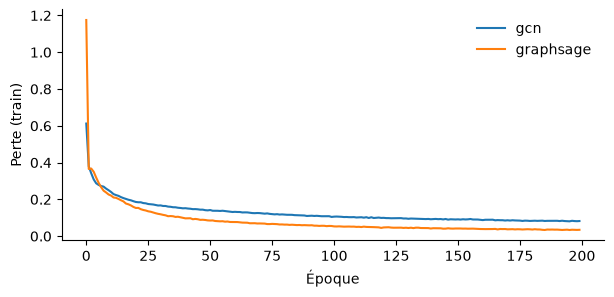

In [3]:
class GNN(torch.nn.Module):
    def __init__(self, conv, d_in, d_h=128):
        super().__init__()
        self.c1, self.c2 = conv(d_in, d_h), conv(d_h, 2)

    def embed(self, x, ei):
        return F.relu(self.c1(x, ei))

    def forward(self, x, ei):
        h = F.dropout(self.embed(x, ei), p=0.3, training=self.training)
        return self.c2(h, ei)


def train_gnn(conv, epochs=200):
    torch.manual_seed(SEED)
    model = GNN(conv, data.num_features)
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    w = torch.tensor([0.3, 0.7])
    losses = []
    for _ in range(epochs):
        model.train(); opt.zero_grad()
        out = model(data.x, data.edge_index)
        loss = F.cross_entropy(out[train_mask], data.y[train_mask], weight=w)
        loss.backward(); opt.step(); losses.append(loss.item())
    model.eval()
    with torch.no_grad():
        prob = model(data.x, data.edge_index).softmax(1)[:, 1]
    return model, prob, losses


models, gnn_prob = {}, {}
fig, ax = plt.subplots(figsize=(7, 3))
for name, conv in [("gcn", GCNConv), ("graphsage", SAGEConv)]:
    t0 = time.time()
    models[name], prob, losses = train_gnn(conv)
    gnn_prob[name] = prob[test_mask].numpy()
    print(f"{name:10s} ({time.time() - t0:.0f} s)", end=" ")
    yt = data.y[test_mask].numpy()
    evaluate(yt, (gnn_prob[name] >= 0.5).astype(int), gnn_prob[name], f"m4_{name}", out_dir=str(RESULTS))
    ax.plot(losses, label=name)
ax.set_xlabel("Époque"); ax.set_ylabel("Perte (train)"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

## 3. Modèle hybride : Random Forest + embeddings GraphSAGE

On récupère la sortie de la première couche de GraphSAGE (128 dimensions par transaction) et on l'ajoute aux 165 features d'origine. Le Random Forest garde sa robustesse sur les features tabulaires et gagne l'information du voisinage.

In [4]:
with torch.no_grad():
    emb = models["graphsage"].embed(data.x, data.edge_index).numpy()
emb_df = pd.DataFrame(emb, index=df.index, columns=[f"emb_{i}" for i in range(emb.shape[1])])
lab_h = pd.concat([lab[feat_cols], emb_df.loc[lab.index]], axis=1)
tr_h, te_h = lab_h[lab.time_step <= 34], lab_h[lab.time_step >= 35]

rf_h = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(tr_h, train.y)
p_hybrid = rf_h.predict_proba(te_h)[:, 1]
evaluate(test.y, (p_hybrid >= 0.5).astype(int), p_hybrid, "m4_rf_plus_graphsage_emb", out_dir=str(RESULTS));

{'recall': 0.716, 'precision': 0.98, 'f1': 0.827, 'pr_auc': 0.792, 'roc_auc': 0.916}


## 4. Comparaison de tous les modèles

Lecture habituelle sur Elliptic : le Random Forest seul bat souvent les GNN simples, et l'hybride fait au moins aussi bien que le Random Forest. Si c'est ce que tu observes, rapporte-le tel quel : c'est un résultat honnête et connu (Weber et al., 2019).

,recall,precision,f1,pr_auc
modèle,,,,
RF,0.722,0.967,0.827,0.795
XGBoost,0.723,0.918,0.809,0.804
RF + ADASYN-TL (Nayyer),0.720,0.878,0.791,0.812
GCN,0.541,0.733,0.623,0.603
GraphSAGE,0.596,0.838,0.697,0.715
RF + emb. GraphSAGE,0.716,0.980,0.827,0.792


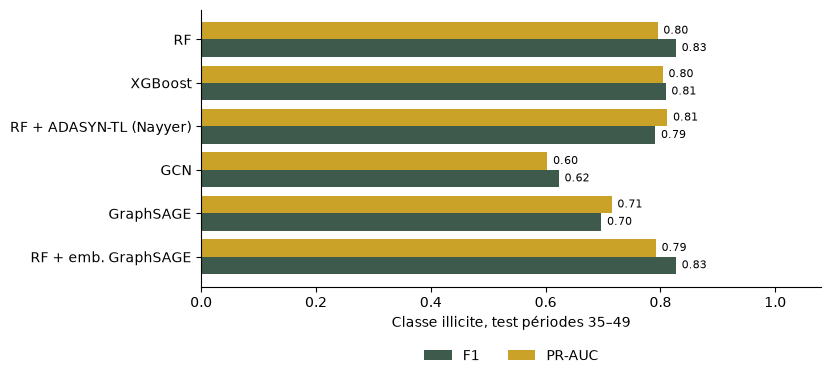

In [5]:
names = {"m4_rf_none": "RF", "m4_xgb_none": "XGBoost", "m4_rf_adasyn_tl": "RF + ADASYN-TL (Nayyer)",
         "m4_gcn": "GCN", "m4_graphsage": "GraphSAGE", "m4_rf_plus_graphsage_emb": "RF + emb. GraphSAGE"}
rows = []
for k, lbl in names.items():
    f = RESULTS / f"{k}.json"
    if f.exists():
        r = json.loads(f.read_text()); rows.append({"modèle": lbl, **{m: r[m] for m in ["recall", "precision", "f1", "pr_auc"]}})
comp = pd.DataFrame(rows).set_index("modèle").round(3)
comp.to_csv(RESULTS / "m4_models_summary.csv")

fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(comp))
ax.barh(y + 0.2, comp.f1, 0.4, label="F1", color="#3d5a4c")
ax.barh(y - 0.2, comp.pr_auc, 0.4, label="PR-AUC", color="#c9a227")
for i, (f1, pr) in enumerate(zip(comp.f1, comp.pr_auc)):
    ax.text(f1 + 0.01, i + 0.2, f"{f1:.2f}", va="center", fontsize=8)
    ax.text(pr + 0.01, i - 0.2, f"{pr:.2f}", va="center", fontsize=8)
ax.set_yticks(y, comp.index); ax.invert_yaxis(); ax.set_xlim(0, 1.08)
ax.set_xlabel("Classe illicite, test périodes 35–49")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(RESULTS / "m4_models_comparison.png", dpi=200, bbox_inches="tight")
comp

## 5. Dérive temporelle

On mesure le F1 **période par période** sur le test (35 à 49), pour trois stratégies :
- **modèle figé** : le Random Forest entraîné une seule fois sur 1–34 (prédictions reprises de `m4_baselines.ipynb`) ;
- **fenêtre glissante** : avant la période *t*, on réentraîne sur les K = 10 périodes précédentes ;
- **fenêtre cumulée** : avant la période *t*, on réentraîne sur toutes les périodes passées.

Hypothèse pour les deux réentraînements : les labels de la période *t − 1* sont connus au moment de prédire *t* (un analyste a confirmé les alertes de la période précédente).

Résultat attendu sur le vrai Elliptic : le modèle figé s'effondre à partir de la **période 43**, quand un grand marché du dark web ferme et que les schémas illicites changent (Weber et al., 2019).

In [9]:
prev = pd.read_csv(PROCESSED / "m4_test_preds.csv").set_index("txId").loc[test.txId]
p_static = prev["p_rf_none"].values
steps = list(range(35, 50))
f1_t = lambda y, p: f1_score(y, p, zero_division=0)

f1_static = [f1_t(test.y[test.time_step == t], p_static[(test.time_step == t).values] >= 0.5) for t in steps]
f1_sage = [f1_t(test.y[test.time_step == t], gnn_prob["graphsage"][(test.time_step == t).values] >= 0.5) for t in steps]

K = 10
f1_window, f1_expand = [], []
for t in steps:
    cur = lab[lab.time_step == t]
    for hist, out in [(lab[(lab.time_step >= t - K) & (lab.time_step <= t - 1)], f1_window),
                      (lab[lab.time_step <= t - 1], f1_expand)]:
        rf_t = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(hist[feat_cols], hist.y)
        out.append(f1_t(cur.y, rf_t.predict(cur[feat_cols])))
    print(t, end=" ")

drift = pd.DataFrame({"periode": steps, "n_illicites": [int(test.y[test.time_step == t].sum()) for t in steps],
                      "rf_fige": f1_static, "graphsage_fige": f1_sage,
                      f"rf_fenetre_{K}": f1_window, "rf_cumule": f1_expand}).round(3)
drift.to_csv(RESULTS / "m4_drift.csv", index=False)
drift

35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 

,periode,n_illicites,rf_fige,graphsage_fige,rf_fenetre_10,rf_cumule
0,35,182,0.978,0.908,0.972,0.978
1,36,33,0.971,0.732,0.985,1.000
2,37,40,0.776,0.667,0.750,0.750
3,38,111,0.948,0.840,0.917,0.948
4,39,81,0.962,0.700,0.905,0.962
5,40,112,0.770,0.663,0.751,0.772
6,41,116,0.964,0.690,0.960,0.960
7,42,239,0.875,0.809,0.878,0.881
8,43,24,0.000,0.000,0.000,0.000
9,44,24,0.062,0.061,0.069,0.071


F1 moyen après la période 43 : figé 0.05 | fenêtre 0.05 | cumulé 0.10


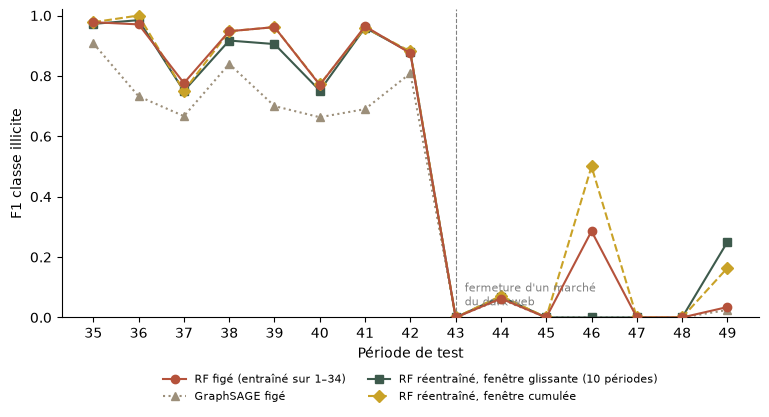

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(steps, f1_static, marker="o", color="#b5523b", zorder=5, label="RF figé (entraîné sur 1–34)")
ax.plot(steps, f1_sage, marker="^", color="#9c8f7a", ls=":", label="GraphSAGE figé")
ax.plot(steps, f1_window, marker="s", color="#3d5a4c", label=f"RF réentraîné, fenêtre glissante ({K} périodes)")
ax.plot(steps, f1_expand, marker="D", color="#c9a227", ls="--", label="RF réentraîné, fenêtre cumulée")
ax.axvline(43, ls="--", c="grey", lw=0.8)
ax.text(43.2, 0.04, "fermeture d'un marché\ndu dark web", fontsize=8, color="grey")
ax.set_xlabel("Période de test"); ax.set_ylabel("F1 classe illicite"); ax.set_ylim(0, 1.02)
ax.set_xticks(steps)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(RESULTS / "m4_drift.png", dpi=200, bbox_inches="tight")

after = drift[drift.periode >= 43]
print(f"F1 moyen après la période 43 : figé {after.rf_fige.mean():.2f} | "
      f"fenêtre {after[f'rf_fenetre_{K}'].mean():.2f} | cumulé {after.rf_cumule.mean():.2f}")

## 6. Sauvegarde

In [11]:
out = test[["txId", "time_step", "y"]].copy()
out["p_gcn"], out["p_graphsage"], out["p_rf_plus_emb"] = gnn_prob["gcn"], gnn_prob["graphsage"], p_hybrid
out.to_csv(PROCESSED / "m4_gnn_preds.csv", index=False)
torch.save(models["graphsage"].state_dict(), PROCESSED / "m4_graphsage.pt")
print("ok :", PROCESSED / "m4_gnn_preds.csv")

ok : ..\data\processed\m4_gnn_preds.csv


## 7. Lecture des résultats (à compléter pour le rapport)

- **Graphe seul** : GCN F1 = … ; GraphSAGE F1 = … ; contre RF F1 = …. GraphSAGE fait mieux que GCN car il garde les features propres du nœud séparées de celles des voisins (concaténation au lieu d'une moyenne).
- **Hybride** : F1 = … (+/− … par rapport au RF seul).
- **Dérive** : F1 moyen après la période 43 : figé … , fenêtre glissante … , cumulé …. Aucune stratégie ne détecte bien le nouveau schéma tant qu'il n'a pas été étiqueté : la réponse est opérationnelle (surveillance + réétiquetage), pas seulement algorithmique.
- **Message pour le jury** : un modèle de détection se surveille et se réentraîne comme une règle de SIEM.